
# Cento Nuptialis Metrical Stylometry with LambdaG

This notebook analyses the stylistic affinities of Ausonius's *Cento Nuptialis* using
LambdaG authorship verification (uncalibrated) on **metrical number-mapped sentences**.

This is the metrical counterpart to `cento_stylometry.ipynb`, which uses POS-masked sentences.

## Setup

Four model corpora are compared against the cento:
- **vergil**: Vergil, *Georgics* (4 books)
- **aeneid**: Vergil, *Aeneid* (12 books)
- **ausonius**: Ausonius hexameter works (17 works, excluding cento)
- **background**: Ovid, Lucan, Silius Italicus, Valerius Flaccus (50 books)

All corpora contain `*_sentences.metrical.txt` files produced by `scripts/generate_metrical.py`.
Each word is replaced by its prime-encoded metrical position number.


In [2]:

from __future__ import annotations

import re
from pathlib import Path

import numpy as np
import pandas as pd
from sentence_corpora import Sentence, TwoLevelCorpus
from sentence_corpora.lambdag import LambdaGAV



## Load Corpora

Each directory contains `*_sentences.metrical.txt` files. We parse the
filenames to extract `(author, work)` metadata and build `TwoLevelCorpus` objects.


In [3]:

def parse_filename(path: Path) -> tuple[str, str]:
    """Parse '<name>_sentences.metrical.txt' into (author, work).

    Filenames from metrical_model/ follow the pattern:
      - ausonius: caesares_sentences.metrical.txt  →  ('caesares', '')
      - vergil: vergil_georgics_1_sentences.metrical.txt  →  ('vergil', 'georgics_1')
      - aeneid: vergil_aeneid_1_sentences.metrical.txt  →  ('vergil', 'aeneid_1')
      - background: ovid_metamorphoses_1_sentences.metrical.txt  →  ('ovid', 'metamorphoses_1')
    """
    name = re.sub(r"_sentences\.metrical\.txt$", "", path.name)
    parts = name.split("_", 1)
    if len(parts) == 1:
        return parts[0], ""
    return parts[0], parts[1]


def load_corpus(data_dir: Path) -> TwoLevelCorpus:
    """Read all *_sentences.metrical.txt files and return a TwoLevelCorpus."""
    sentences = []
    for path in sorted(data_dir.glob("*_sentences.metrical.txt")):
        author, work = parse_filename(path)
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if line:
                    sentences.append(Sentence(text=line, metadata={"author": author, "work": work}))
    return TwoLevelCorpus(sentences, levels=["author", "work"])


# Load the four model corpora
vergil_corpus = load_corpus(Path("metrical_model/vergil"))
aeneid_corpus = load_corpus(Path("metrical_model/aeneid"))
ausonius_corpus = load_corpus(Path("metrical_model/ausonius"))
background_corpus = load_corpus(Path("metrical_model/background"))

# Load the question text (cento)
cento_path = Path("metrical_model/question/cento_nuptialis_sentences.metrical.txt")
cento_sentences = []
with open(cento_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            cento_sentences.append(Sentence(text=line, metadata={"author": "cento", "work": "nuptialis"}))
cento_corpus = TwoLevelCorpus(cento_sentences, levels=["author", "work"])

print(f"Vergil (Georgics):  {len(vergil_corpus)} sentences, {sum(len(s.text.split()) for s in vergil_corpus)} tokens")
print(f"Aeneid:             {len(aeneid_corpus)} sentences, {sum(len(s.text.split()) for s in aeneid_corpus)} tokens")
print(f"Ausonius:           {len(ausonius_corpus)} sentences, {sum(len(s.text.split()) for s in ausonius_corpus)} tokens")
print(f"Background:         {len(background_corpus)} sentences, {sum(len(s.text.split()) for s in background_corpus)} tokens")
print(f"Cento (question):   {len(cento_corpus)} sentences, {sum(len(s.text.split()) for s in cento_corpus)} tokens")


Vergil (Georgics):  809 sentences, 17169 tokens
Aeneid:             4314 sentences, 77977 tokens
Ausonius:           959 sentences, 17355 tokens
Background:         15111 sentences, 295589 tokens
Cento (question):   58 sentences, 1013 tokens


In [4]:

vergil_corpus[:10]


[Sentence(text='2 18 4 18 2 18 4 <EOL> 18 8 4 396 4 <EOL> 36 2 6 6...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='2 2 36 4 <EOL> 18 8 4 2 18 4 <EOL> <EOS>...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='6 3 6 6 4 2 18 4 <EOL> 36 4 4 12 12 <EOL> 18 88 16...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='2 2 8 36 18 4 <EOL> <EOS>...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='6 6 12 6 54 12 <EOL> 18 6 6 <EOS>...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='2 22 2 6 12 <EOL> 6 6 4 4 12 12 <EOL> 20 <EOS>...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='2 4 18 2 18 4 <EOL> 2 4 18 4 12 12 <EOL> <EOS>...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='6 6 4 18 12 12 <EOL> 2 18 4 9 2 9 18 4 <EOL> 4 2 5...', metadata={'author': 'vergil', 'work': 'georgics_1'}),
 Sentence(text='2 198 2 2 2 2 54 12 <EOL> 90 20 2 20

In [5]:

cento_corpus[:10]


[Sentence(text='90 2 18 4 396 4 <EOL> 10 18 10 8 36 4 <EOL> 4 8 9 ...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='2 2 36 6 3 4 <EOL> 36 54 6 <EOS>...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='2 12 6 <EOS>...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='9 2 132 12 <EOL> 24 6 <EOS>...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='9 6 54 2 2 <EOL> <EOS>...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='24 6 18 4 396 <EOL> 4 6 6 18 10 6 12 <EOL> 36 12 6...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='2 18 18 4 54 12 <EOL> 6 24 18 12 12 <EOL> 18 6 6 <...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='18 36 4 <EOL> 36 54 6 54 12 <EOL> 2 4 4 3 66 12 12...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(text='10 18 12 6 2 18 4 <EOL> <EOS>...', metadata={'author': 'cento', 'work': 'nuptialis'}),
 Sentence(te

In [6]:
ausonius_corpus[:10]

[Sentence(text='36 18 2 4 6 12 <EOL> 36 4 12 54 4 <EOL> 18 2 4 <EO...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='9 6 54 4 <EOL> 4 2 4 18 36 4 <EOL> 18 2 4 4 594 12...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='4 8 36 18 4 <EOL> 6 3 8 4 12 3 4 <EOL> <EOS>...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='8 2 2 4 9 18 2 2 <EOL> 4 8 18 2 6 12 <EOL> <EOS>...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='18 2 18 4 2 2 9 4 <EOL> 18 36 <EOS>...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='2 2 2 2 9 4 <EOL> 6 6 4 18 12 12 <EOL> 6 15 8 2 4 ...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='2 18 4 88 72 <EOL> 2 9 36 4 54 <EOS>...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='12 <EOL> 4 2 4 4 9 6 12 <EOL> <EOS>...', metadata={'author': 'ausonius', 'work': 'caesares'}),
 Sentence(text='18 2 18 4 162 4 <EOL> <EOS>.


## Run LambdaG Authorship Verification (Uncalibrated)

For each candidate author, we run a single AV problem:
- **q_corpus**: the cento (question text)
- **kr_corpus**: the model corpus (known reference)
- **known_entity**: the author label in the model corpus

The `LambdaGAV.run_single_av_problem` method computes a raw score indicating
how similar the question text is to the known author. Higher scores = more similar.


In [7]:

# Run LambdaG AV for each candidate author
# The cento is small (~900 tokens), so we use conservative known/reference token counts
av = LambdaGAV()
rng = np.random.default_rng(42)

results = []

for candidate, candidate_corpus in [("vergil", vergil_corpus), ("ausonius", ausonius_corpus)]:

    # Combine candidate + background into a single KR corpus
    kr_sentences = list(candidate_corpus) + list(background_corpus)
    kr_corpus = TwoLevelCorpus(kr_sentences, levels=["author", "work"])    

    result = av.run_single_av_problem(
        known_entity=candidate,
        q_corpus=cento_corpus,
        kr_corpus=kr_corpus,
        known_tokens=15000,
        reference_tokens=30000,
        order=10,
        num_references=50,
        rng=rng,
    )
    
    results.append({
        "candidate": candidate,
        "score": result.get("score", 0.0),
        "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
        "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
        "n_unknown": result.get("unknown_sentences_used", 0),
        "unknown_tokens": result.get("unknown_tokens_used", 0),
        "n_known": result.get("known_sentences_used", 0),
        "n_reference": result.get("reference_sentences_used", 0),
        "error": result.get("error", None),
    })
    print(f"  {candidate}: score={results[-1]['score']:.4f}, tokens_q={results[-1]['unknown_tokens']}")

print("\nDone.")


  vergil: score=120.0119, tokens_q=1013
  ausonius: score=-17.5817, tokens_q=1013

Done.



## Results


In [8]:

df = pd.DataFrame(results)
df = df.sort_values("score", ascending=False)

# Calculate probabilities from both corrected LLRs using prior=0.5
PRIOR = 0.5
df["prob_sqrt"] = df["corrected_score_sqrt"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)
df["prob_hapax"] = df["corrected_score_hapax"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)

print("LambdaG Metrical Results (uncalibrated, prior=0.5):")
print("=" * 80)
for _, row in df.iterrows():
    print(f"  {row['candidate']:<12}  raw={row['score']:>8.4f}"
          f"  sqrt={row['corrected_score_sqrt']:>8.4f} -> {row['prob_sqrt']:>6.1f}%"
          f"  hapax={row['corrected_score_hapax']:>8.4f} -> {row['prob_hapax']:>6.1f}%"
          f"  (q_tokens={row['unknown_tokens']})")


LambdaG Metrical Results (uncalibrated, prior=0.5):
  vergil        raw=120.0119  sqrt=  3.7707 ->   97.7%  hapax=  1.0662 ->   74.4%  (q_tokens=1013)
  ausonius      raw=-17.5817  sqrt= -0.5524 ->   36.5%  hapax= -0.1562 ->   46.1%  (q_tokens=1013)



## Aeneid vs Vergil (Georgics) — Baseline Check


In [9]:

from typing import Any


def sample_corpus_to_token_count(corpus, target_tokens: int, rng: Any):
    """Sample sentences from corpus until we reach approximately target_tokens."""
    sentences = list(corpus)
    total_tokens = sum(len(s.text.split()) for s in sentences)

    if total_tokens <= target_tokens:
        raise ValueError(
            f"Corpus has only {total_tokens} tokens, which is less than target {target_tokens}"
        )

    shuffled = list(sentences)
    rng.shuffle(shuffled)

    sampled = []
    current_tokens = 0
    for s in shuffled:
        sampled.append(s)
        current_tokens += len(s.text.split())
        if current_tokens >= target_tokens:
            break

    return type(corpus)(sampled, levels=corpus.levels)


print(f"Aeneid corpus: {len(aeneid_corpus)} sentences, {sum(len(s.text.split()) for s in aeneid_corpus)} tokens")


Aeneid corpus: 4314 sentences, 77977 tokens


In [10]:

import ray
from tqdm import tqdm

# Run N iterations: sample ~1079 tokens from Aeneid, compare against Vergil (Georgics) + background
TARGET_TOKENS = 1013
NUM_ITERATIONS = 100

# KR corpus = vergil (Georgics) + background
kr_sentences = list(vergil_corpus) + list(background_corpus)
kr_corpus = TwoLevelCorpus(kr_sentences, levels=["author", "work"])


@ray.remote
def run_aeneid_iteration(i: int) -> dict:
    """Run a single Aeneid vs Vergil AV iteration."""
    iter_rng = np.random.default_rng(42 + i)
    q_corpus = sample_corpus_to_token_count(aeneid_corpus, TARGET_TOKENS, iter_rng)
    actual_tokens = sum(len(s.text.split()) for s in q_corpus)

    av = LambdaGAV()
    result = av.run_single_av_problem(
        known_entity="vergil",
        q_corpus=q_corpus,
        kr_corpus=kr_corpus,
        known_tokens=15000,
        reference_tokens=30000,
        order=10,
        num_references=10,
        rng=iter_rng,
    )

    return {
        "iteration": i,
        "score": result.get("score", 0.0),
        "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
        "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
        "q_tokens": actual_tokens,
        "n_known": result.get("known_sentences_used", 0),
        "n_reference": result.get("reference_sentences_used", 0),
        "error": result.get("error", None),
    }


ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

tasks = [run_aeneid_iteration.remote(i) for i in range(NUM_ITERATIONS)]

aeneid_results = []
for _ in tqdm(range(len(tasks)), desc="Aeneid AV"):
    ready, tasks = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    aeneid_results.append(result)

ray.shutdown()
print("\nDone.")


2026-07-25 10:19:42,042	INFO worker.py:2024 -- Started a local Ray instance.


Ray initialized with 10.0 CPUs


Aeneid AV: 100%|██████████| 100/100 [01:43<00:00,  1.04s/it]



Done.


In [11]:

df_aeneid = pd.DataFrame(aeneid_results)

PRIOR = 0.5
df_aeneid["prob_sqrt"] = df_aeneid["corrected_score_sqrt"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)
df_aeneid["prob_hapax"] = df_aeneid["corrected_score_hapax"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)

print(f"Aeneid vs Vergil (Georgics) — {NUM_ITERATIONS} iterations, ~{TARGET_TOKENS} tokens each, prior={PRIOR}")
print("=" * 100)
print(f"{'iter':>4}  {'raw':>8}  {'sqrt':>8}  {'prob_sqrt':>10}  {'hapax':>8}  {'prob_hapax':>10}  {'q_tok':>6}")
print("-" * 100)
for _, row in df_aeneid.iterrows():
    print(f"  {int(row['iteration']):>2}  {row['score']:>8.4f}  {row['corrected_score_sqrt']:>8.4f}"
          f"  {row['prob_sqrt']:>9.1f}%  {row['corrected_score_hapax']:>8.4f}"
          f"  {row['prob_hapax']:>9.1f}%  {int(row['q_tokens']):>6}")
print("-" * 100)
print(f"{'mean':>4}  {df_aeneid['score'].mean():>8.4f}  {df_aeneid['corrected_score_sqrt'].mean():>8.4f}"
      f"  {df_aeneid['prob_sqrt'].mean():>9.1f}%  {df_aeneid['corrected_score_hapax'].mean():>8.4f}"
      f"  {df_aeneid['prob_hapax'].mean():>9.1f}%")
print(f"{'std':>4}  {df_aeneid['score'].std():>8.4f}  {df_aeneid['corrected_score_sqrt'].std():>8.4f}"
      f"  {df_aeneid['prob_sqrt'].std():>9.1f}%  {df_aeneid['corrected_score_hapax'].std():>8.4f}"
      f"  {df_aeneid['prob_hapax'].std():>9.1f}%")


Aeneid vs Vergil (Georgics) — 100 iterations, ~1013 tokens each, prior=0.5
iter       raw      sqrt   prob_sqrt     hapax  prob_hapax   q_tok
----------------------------------------------------------------------------------------------------
   3   95.2312    2.9760       95.1%    0.3720       59.2%    1024
   0   88.1117    2.7630       94.1%    0.5198       62.7%    1017
   8   31.3854    0.9760       72.6%    0.2125       55.3%    1034
   9   71.0246    2.1898       89.9%    0.6076       64.7%    1052
   2   51.3437    1.5975       83.2%    0.3479       58.6%    1033
   6   39.5593    1.2399       77.6%    0.1554       53.9%    1018
   7  156.6702    4.9104       99.3%    0.7695       68.3%    1018
   5   96.6851    3.0303       95.4%    0.8548       70.2%    1018
   4  128.9171    4.0306       98.3%    1.1342       75.7%    1023
   1   78.0149    2.4226       91.9%    0.9028       71.2%    1037
  15   42.9975    1.3398       79.2%    0.2087       55.2%    1030
  12   50.8908    1.


## Mosella vs Ausonius — Internal Baseline


In [12]:

# Build Mosella corpus (q) and Ausonius-minus-Mosella corpus (kr)
mosella_sentences = [s for s in ausonius_corpus if s.work == "mosella"]
ausonius_no_mosella_sentences = [s for s in ausonius_corpus if s.work != "mosella"]

mosella_corpus = TwoLevelCorpus(mosella_sentences, levels=["author", "work"])
ausonius_no_mosella = TwoLevelCorpus(ausonius_no_mosella_sentences, levels=["author", "work"])

# KR corpus = ausonius (without mosella) + background
kr_ausonius_sentences = list(ausonius_no_mosella) + list(background_corpus)
kr_ausonius_corpus = TwoLevelCorpus(kr_ausonius_sentences, levels=["author", "work"])

print(f"Mosella corpus: {len(mosella_corpus)} sentences, {sum(len(s.text.split()) for s in mosella_corpus)} tokens")
print(f"Ausonius (excl. Mosella): {len(ausonius_no_mosella)} sentences, {sum(len(s.text.split()) for s in ausonius_no_mosella)} tokens")
print(f"KR corpus (Ausonius excl. Mosella + background): {len(kr_ausonius_corpus)} sentences")


@ray.remote
def run_mosella_iteration(i: int) -> dict:
    """Run a single Mosella vs Ausonius AV iteration."""
    iter_rng = np.random.default_rng(100 + i)
    q_corpus = sample_corpus_to_token_count(mosella_corpus, TARGET_TOKENS, iter_rng)
    actual_tokens = sum(len(s.text.split()) for s in q_corpus)

    av = LambdaGAV()
    result = av.run_single_av_problem(
        known_entity="ausonius",
        q_corpus=q_corpus,
        kr_corpus=kr_ausonius_corpus,
        known_tokens=13000,
        reference_tokens=20000,
        order=10,
        num_references=10,
        rng=iter_rng,
    )

    return {
        "iteration": i,
        "score": result.get("score", 0.0),
        "corrected_score_sqrt": result.get("corrected_score_sqrt", 0.0),
        "corrected_score_hapax": result.get("corrected_score_hapax", 0.0),
        "q_tokens": actual_tokens,
        "n_known": result.get("known_sentences_used", 0),
        "n_reference": result.get("reference_sentences_used", 0),
        "error": result.get("error", None),
    }


ray.init(ignore_reinit_error=True)

tasks = [run_mosella_iteration.remote(i) for i in range(NUM_ITERATIONS)]

mosella_results = []
for _ in tqdm(range(len(tasks)), desc="Mosella AV"):
    ready, tasks = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    mosella_results.append(result)

ray.shutdown()
print("\nDone.")


Mosella corpus: 163 sentences, 3577 tokens
Ausonius (excl. Mosella): 796 sentences, 13778 tokens
KR corpus (Ausonius excl. Mosella + background): 15907 sentences


2026-07-25 10:21:29,847	INFO worker.py:2024 -- Started a local Ray instance.
Mosella AV: 100%|██████████| 100/100 [01:47<00:00,  1.07s/it]



Done.


In [13]:

df_mosella = pd.DataFrame(mosella_results)

df_mosella["prob_sqrt"] = df_mosella["corrected_score_sqrt"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)
df_mosella["prob_hapax"] = df_mosella["corrected_score_hapax"].apply(
    lambda s: LambdaGAV.llr_to_percent_probability(s, PRIOR)
)

print(f"Mosella vs Ausonius — {NUM_ITERATIONS} iterations, ~{TARGET_TOKENS} tokens each, prior={PRIOR}")
print("=" * 100)
print(f"{'iter':>4}  {'raw':>8}  {'sqrt':>8}  {'prob_sqrt':>10}  {'hapax':>8}  {'prob_hapax':>10}  {'q_tok':>6}")
print("-" * 100)
for _, row in df_mosella.iterrows():
    print(f"  {int(row['iteration']):>2}  {row['score']:>8.4f}  {row['corrected_score_sqrt']:>8.4f}"
          f"  {row['prob_sqrt']:>9.1f}%  {row['corrected_score_hapax']:>8.4f}"
          f"  {row['prob_hapax']:>9.1f}%  {int(row['q_tokens']):>6}")
print("-" * 100)
print(f"{'mean':>4}  {df_mosella['score'].mean():>8.4f}  {df_mosella['corrected_score_sqrt'].mean():>8.4f}"
      f"  {df_mosella['prob_sqrt'].mean():>9.1f}%  {df_mosella['corrected_score_hapax'].mean():>8.4f}"
      f"  {df_mosella['prob_hapax'].mean():>9.1f}%")
print(f"{'std':>4}  {df_mosella['score'].std():>8.4f}  {df_mosella['corrected_score_sqrt'].std():>8.4f}"
      f"  {df_mosella['prob_sqrt'].std():>9.1f}%  {df_mosella['corrected_score_hapax'].std():>8.4f}"
      f"  {df_mosella['prob_hapax'].std():>9.1f}%")


Mosella vs Ausonius — 100 iterations, ~1013 tokens each, prior=0.5
iter       raw      sqrt   prob_sqrt     hapax  prob_hapax   q_tok
----------------------------------------------------------------------------------------------------
   0   94.2708    2.9289       94.9%    0.9099       71.3%    1036
   8  192.3726    6.0293       99.8%    1.7007       84.6%    1018
   3   42.1461    1.3190       78.9%    0.4541       61.2%    1021
   4   39.4689    1.2298       77.4%    0.2682       56.7%    1030
   1  141.9821    4.4283       98.8%    0.9668       72.4%    1028
   6   88.1985    2.7468       94.0%    0.9410       71.9%    1031
   2    0.7400    0.0232       50.6%    0.0036       50.1%    1017
   5    1.3081    0.0409       51.0%    0.0102       50.3%    1022
   7   84.9498    2.6354       93.3%    0.4906       62.0%    1039
   9  180.4528    5.6364       99.6%    1.2324       77.4%    1025
  11   63.5466    1.9743       87.8%    0.4294       60.6%    1036
  10  138.0470    4.3056    


## Visualisation: Baseline Score Distributions with Cento Markers


Font name: `Roboto Condensed`


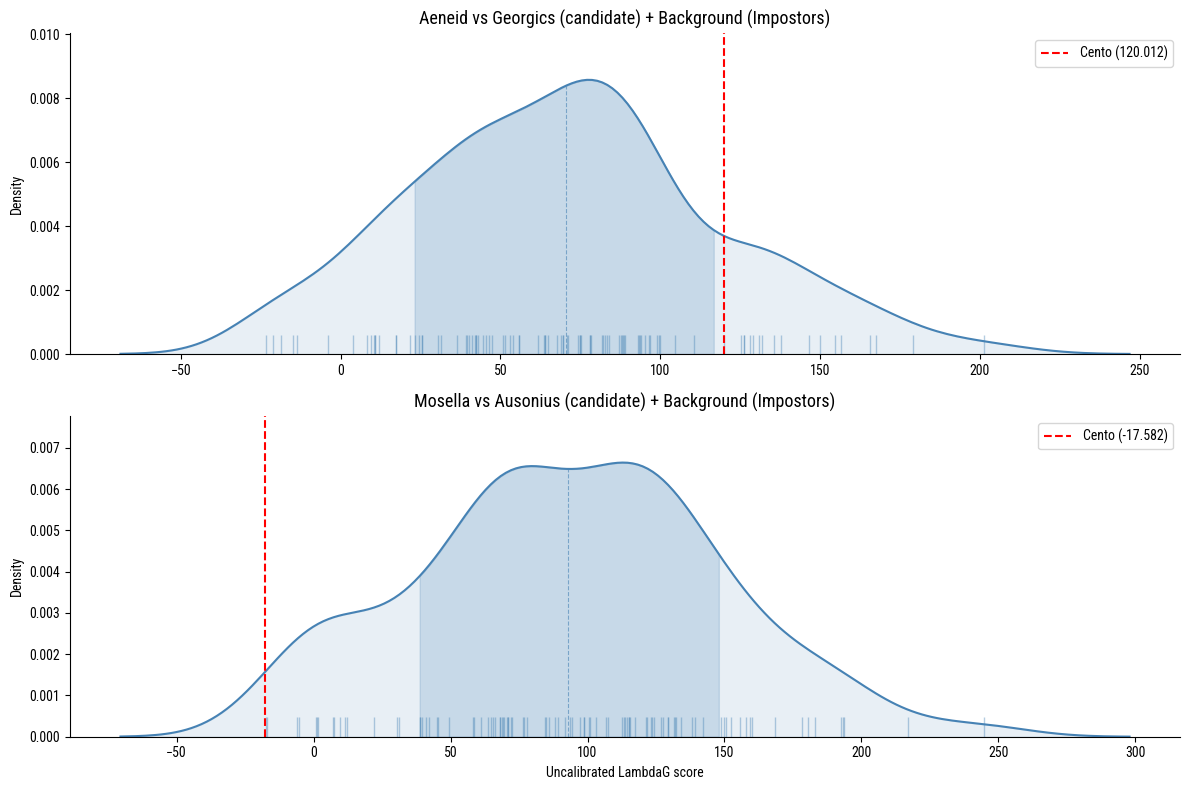

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import mpl_fontkit as fk

fk.install("Roboto Condensed")
plt.rcParams["font.family"] = "Roboto Condensed"

cento_vergil_score = df.loc[df["candidate"] == "vergil", "score"].values[0]
cento_ausonius_score = df.loc[df["candidate"] == "ausonius", "score"].values[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))


def plot_baseline(ax, data, cento_score, title, xlabel=""):
    scores = data["score"]
    mean = scores.mean()
    sd = scores.std()

    # KDE as a line (no fill) so we can extract coordinates
    sns.kdeplot(data=data, x="score", ax=ax, color="steelblue",
                linewidth=1.5, fill=False, bw_adjust=0.8)
    sns.rugplot(data=data, x="score", ax=ax, color="steelblue",
                alpha=0.4, height=0.06)

    # Extract curve coordinates
    line = ax.lines[0]
    x_data, y_data = line.get_data()

    # Fill the curve manually
    ax.fill_between(x_data, y_data, alpha=0.12, color="steelblue")

    # Shade ±1 SD region
    mask = (np.array(x_data) >= mean - sd) & (np.array(x_data) <= mean + sd)
    ax.fill_between(np.array(x_data)[mask], np.array(y_data)[mask],
                    alpha=0.2, color="steelblue")

    # Mean dashed line — stops at curve height
    mean_y = float(np.interp(mean, x_data, y_data))
    ax.vlines(mean, 0, mean_y, colors="steelblue", linewidth=0.8,
              linestyles="--", alpha=0.6)

    # Cento marker (full height)
    ax.axvline(cento_score, color="red", linewidth=1.5, linestyle="--",
               label=f"Cento ({cento_score:.3f})")

    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=10, loc="upper right")
    sns.despine(ax=ax)


plot_baseline(axes[0], df_aeneid, cento_vergil_score,
              "Aeneid vs Georgics (candidate) + Background (Impostors)")

plot_baseline(axes[1], df_mosella, cento_ausonius_score,
              "Mosella vs Ausonius (candidate) + Background (Impostors)",
              xlabel="Uncalibrated LambdaG score")

plt.tight_layout()
plt.show()

Font name: `Roboto Condensed`


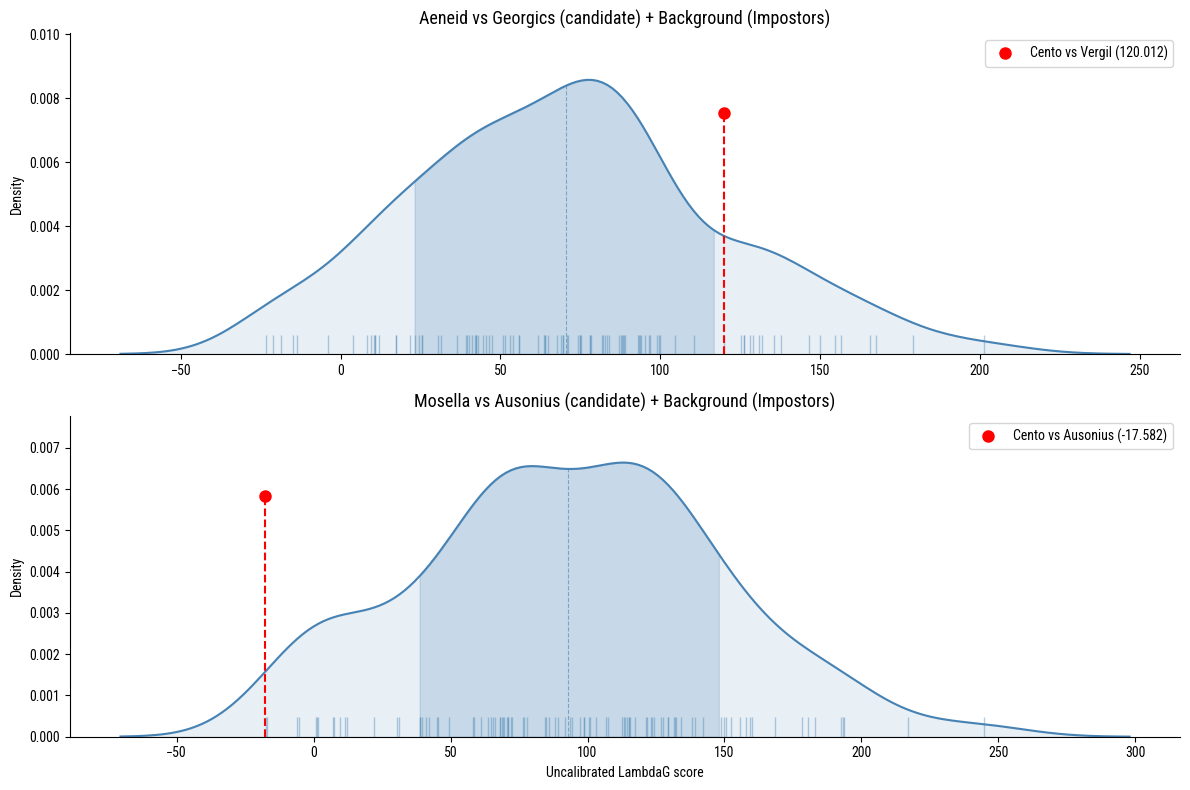

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import mpl_fontkit as fk

fk.install("Roboto Condensed")
plt.rcParams["font.family"] = "Roboto Condensed"

cento_vergil_score = df.loc[df["candidate"] == "vergil", "score"].values[0]
cento_ausonius_score = df.loc[df["candidate"] == "ausonius", "score"].values[0]

fig, axes = plt.subplots(2, 1, figsize=(12, 8))


def plot_baseline(ax, data, cento_score, title, candidate, xlabel=""):
    scores = data["score"]
    mean = scores.mean()
    sd = scores.std()

    # KDE as a line (no fill) so we can extract coordinates
    sns.kdeplot(data=data, x="score", ax=ax, color="steelblue",
                linewidth=1.5, fill=False, bw_adjust=0.8)
    sns.rugplot(data=data, x="score", ax=ax, color="steelblue",
                alpha=0.4, height=0.06)

    # Extract curve coordinates
    line = ax.lines[0]
    x_data, y_data = line.get_data()

    # Fill the curve manually
    ax.fill_between(x_data, y_data, alpha=0.12, color="steelblue")

    # Shade ±1 SD region
    mask = (np.array(x_data) >= mean - sd) & (np.array(x_data) <= mean + sd)
    ax.fill_between(np.array(x_data)[mask], np.array(y_data)[mask],
                    alpha=0.2, color="steelblue")

    # Mean dashed line — stops at curve height
    mean_y = float(np.interp(mean, x_data, y_data))
    ax.vlines(mean, 0, mean_y, colors="steelblue", linewidth=0.8,
              linestyles="--", alpha=0.6)

    # Cento lollipop marker
    ax.axvline(cento_score, ymax=0.75, color="red", linewidth=1.5, linestyle="--")
    cento_y = ax.get_ylim()[1] * 0.75
    ax.plot(cento_score, cento_y, "o", color="red", markersize=8,
            label=f"Cento vs {candidate} ({cento_score:.3f})")

    ax.set_title(title, fontsize=13)
    ax.set_xlabel(xlabel)
    ax.legend(fontsize=10, loc="upper right")
    sns.despine(ax=ax)


plot_baseline(axes[0], df_aeneid, cento_vergil_score,
              "Aeneid vs Georgics (candidate) + Background (Impostors)", "Vergil")

plot_baseline(axes[1], df_mosella, cento_ausonius_score,
              "Mosella vs Ausonius (candidate) + Background (Impostors)", "Ausonius",
              xlabel="Uncalibrated LambdaG score")

plt.tight_layout()
plt.show()